In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/processed/customer_features.csv")

In [2]:
df.head()

,customer_id,total_inflow,total_outflow,net_cash_flow,transaction_count,average_transaction_amount
0,CUST0001,659885.23,278504.28,381380.95,61,15383.434590
1,CUST0002,1099531.21,446362.23,653168.98,66,23422.627879
2,CUST0003,594970.58,183924.10,411046.48,52,14978.743846
3,CUST0004,529626.54,167402.44,362224.10,41,17000.706829
4,CUST0005,1103806.64,381336.67,722469.97,58,25605.919138


In [4]:
df.shape

(600, 6)

In [5]:
df["customer_id"].duplicated().sum()

np.int64(0)

In [6]:
df.isna().sum()

customer_id                   0
total_inflow                  0
total_outflow                 0
net_cash_flow                 0
transaction_count             0
average_transaction_amount    0
dtype: int64

In [7]:
np.isinf(df.select_dtypes(include = "number")).sum()

total_inflow                  0
total_outflow                 0
net_cash_flow                 0
transaction_count             0
average_transaction_amount    0
dtype: int64

In [10]:
features = df.drop(columns = ["customer_id"])

features.head()

,total_inflow,total_outflow,net_cash_flow,transaction_count,average_transaction_amount
0,659885.23,278504.28,381380.95,61,15383.434590
1,1099531.21,446362.23,653168.98,66,23422.627879
2,594970.58,183924.10,411046.48,52,14978.743846
3,529626.54,167402.44,362224.10,41,17000.706829
4,1103806.64,381336.67,722469.97,58,25605.919138


In [12]:
scaler = StandardScaler()

scaled_features = scaler.fit_transform(features)

scaled_df = pd.DataFrame(
    scaled_features, columns = features.columns
)

scaled_df.head()

,total_inflow,total_outflow,net_cash_flow,transaction_count,average_transaction_amount
0,0.440706,-0.410453,0.564739,1.026002,-0.206936
1,2.289146,1.036148,1.571569,1.765729,1.662928
2,0.167780,-1.225546,0.674634,-0.305507,-0.301065
3,-0.106952,-1.367930,0.493773,-1.932907,0.169231
4,2.307122,0.475757,1.828293,0.582165,2.170748


In [13]:
print("Feature means:")
print(scaled_df.mean().round(2))

print("\nFeature standard deviations:")
print(scaled_df.std(ddof=0).round(2))

Feature means:
total_inflow                  0.0
total_outflow                -0.0
net_cash_flow                -0.0
transaction_count             0.0
average_transaction_amount   -0.0
dtype: float64

Feature standard deviations:
total_inflow                  1.0
total_outflow                 1.0
net_cash_flow                 1.0
transaction_count             1.0
average_transaction_amount    1.0
dtype: float64


## Elbow method to choose cluster count

In [14]:
inertia_values = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(n_clusters = k, random_state = 42, n_init = 10)
    model.fit(scaled_df)

    inertia_values.append(model.inertia_)





In [33]:
print([f"{x:.2f}" for x in inertia_values])

['1938.45', '1512.36', '1306.75', '1122.68', '977.72', '853.05', '791.98']


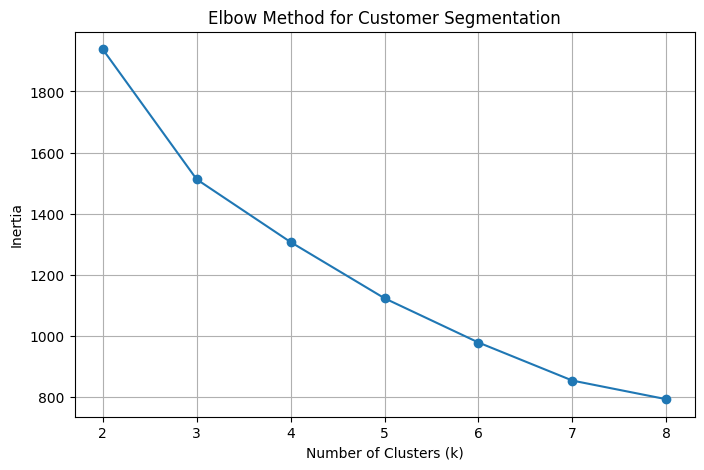

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")

plt.xticks(list(k_values))
plt.grid(True)
plt.show()

## Silhouette scores

In [34]:
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters = k, random_state=42, n_init = 10)
    cluster_labels = model.fit_predict(scaled_df)

    score = silhouette_score(scaled_df, cluster_labels)

    silhouette_values.append(score)

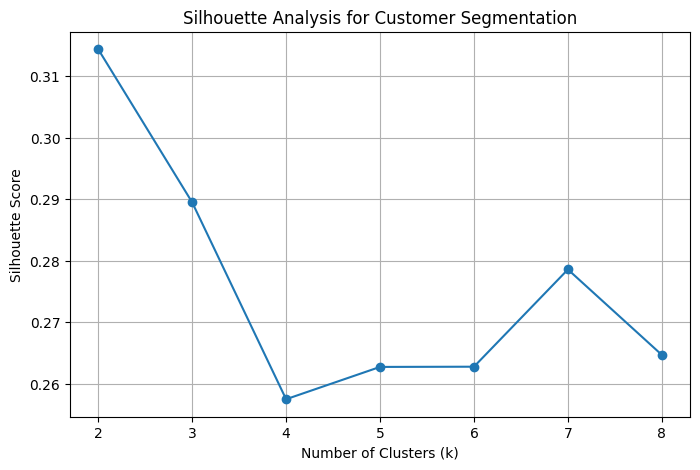

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for Customer Segmentation")

plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [38]:
best_k = 2

Kmeans = KMeans(n_clusters = best_k, random_state=42, n_init = 10)

df["cluster"] = Kmeans.fit_predict(scaled_df)

df[["customer_id", "cluster"]].head()

,customer_id,cluster
0,CUST0001,1
1,CUST0002,1
2,CUST0003,1
3,CUST0004,0
4,CUST0005,1


In [39]:
cluster_profiles = df.groupby("cluster")[
    [
        "total_inflow",
        "total_outflow",
        "net_cash_flow",
        "transaction_count",
        "average_transaction_amount"
    ]
].mean().round(2)

cluster_profiles

,total_inflow,total_outflow,net_cash_flow,transaction_count,average_transaction_amount
cluster,,,,,
0,391865.40,326648.69,65216.71,52.21,13826.82
1,788301.01,325392.76,462908.25,56.72,19769.26


In [ ]:
df["cluster"].value_counts().sort_index()

cluster
0    353
1    247
Name: count, dtype: int64